## Evaluation and validation of the effective borehole thermal resistance

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter

import pygfunction3 as gt3
import pygfunction as gt
from bhr.borehole import Borehole as Borehole_bhr

#### Borehole parameters
A straight vertical borehole located at the origin (x=0, y=0) is used since the model is only dependent on the longitudinal position along the borehole.

In [2]:
# Borehole dimensions
L = 200.      # Borehole length (in meters)
D = 4.        # Borehole buried depth (in meters)
r_b = 0.0635  # Borehole radius (in meters)
x = 0.        # Borehole position x on the horizontal plane (in meters)
y = 0.        # Borehole position y on the horizontal plane (in meters)
borehole = gt3.Borehole(L, D, r_b, [x, y])

# Pipe dimensions
# Pipe outer radius (m)
r_p_out = 0.016
# Dimension ratio
d_r = 11
# Pipe inner radius (m)
r_p_in = r_p_out * (1 - 1 / d_r)

# Pipe positions
# Shank spacing
shank = 0.032
# Single U-tube
p_single = [(-shank, 0.0), (shank, 0.0)]
# Double U-tube (diagonal)
p_diagonal = [(-shank, 0.0), (shank, 0.0), (0.0, -shank), (0.0, shank)]
# Double U-tube (adjacent)
p_adjacent = [(-shank, 0.0), (0.0, -shank), (shank, 0.0), (0.0, shank)]

# Pipe properties
k_p = 0.4           # Pipe thermal conductivity (W/m.K)
epsilon = 2.12e-5   # Pipe roughness (in meters)

# Ground properties
k_s = 2.0           # Ground thermal conductivity (W/m.K)

# Grout properties
k_b = 1.6           # Grout thermal conductivity (W/m.K)

#### Fluid Properties
The fluid is propylene-glycol (20%) and the internal thermal resistances were calculated for a typical borehole configuration using the multipole method.

In [3]:
# Fluid mass flow rate (in kg/s)
m_flow = np.linspace(0.01, 1.0, num=100)
T_nominal = 20.
x = 0.2
fluid = gt3.Fluid.from_scp(
    'PropyleneGlycol', T_nominal, x=x
)
cp_f = fluid.specific_heat()  # Fluid specific heat capacity (in J/kg.K)

### Single U-tube

In [4]:
# pygfunction v3
tic0 = perf_counter()
single_u_tube = gt3.pipe.SingleUTube(p_single, r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)
toc0 = perf_counter()
single_u_tube_reversed = gt3.pipe.SingleUTube(p_single[::-1], r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)
# pygfunction v2
tic1 = perf_counter()
borehole_pygfunction = gt.boreholes.Borehole(L, D, r_b, x, y)
h_fluid = np.array([
    gt.pipes.convective_heat_transfer_coefficient_circular_pipe(
        _m_flow,
        r_p_in,
        fluid.viscosity(),
        fluid.density(),
        fluid.conductivity(),
        fluid.specific_heat(),
        epsilon
        )
    for _m_flow in m_flow
])
R_fluid = 1. / (h_fluid * 2. * np.pi * r_p_in)
R_pipe = gt.pipes.conduction_thermal_resistance_circular_pipe(
    r_p_in, r_p_out, k_p
)
R_fp = R_fluid + R_pipe
single_u_tube_pygfunction = [
    gt.pipes.SingleUTube(
        p_single, r_p_in, r_p_out, borehole_pygfunction, k_s, k_b, _R_fp, J=3
    )
    for _R_fp in R_fp
]
toc1 = perf_counter()
# BHResist
tic2 = perf_counter()
single_u_tube_bhr = Borehole_bhr()
single_u_tube_bhr.init_single_u_borehole(
    borehole_diameter=2*r_b,
    pipe_outer_diameter=2*r_p_out,
    pipe_dimension_ratio=d_r,
    length=L,
    shank_space=shank,
    pipe_conductivity=k_p,
    grout_conductivity=k_b,
    soil_conductivity=k_s,
    fluid_type="PROPYLENEGLYCOL",
    fluid_concentration=x,
    boundary_condition="UNIFORM_BOREHOLE_WALL_TEMP",
)
toc2 = perf_counter()

In [5]:
print(f"Initialization time for pygfunction v3: {toc0 - tic0:.6f} seconds")
print(f"Initialization time for pygfunction v2: {toc1 - tic1:.6f} seconds")
print(f"Initialization time for BHResist: {toc2 - tic2:.6f} seconds")

Initialization time for pygfunction v3: 0.000174 seconds
Initialization time for pygfunction v2: 0.260936 seconds
Initialization time for BHResist: 0.000122 seconds


In [6]:
tic0 = perf_counter()
R_b_eff = np.array([single_u_tube.effective_borehole_thermal_resistance(borehole, _m_flow) for _m_flow in m_flow])
toc0 = perf_counter()
R_b_eff_reversed = np.array([single_u_tube_reversed.effective_borehole_thermal_resistance(borehole, -_m_flow) for _m_flow in m_flow])
tic1 = perf_counter()
R_b_eff_pygfunction = np.array([single_u_tube_pygfunction[i].effective_borehole_thermal_resistance(_m_flow, np.array([cp_f])) for i, _m_flow in enumerate(m_flow)])
toc1 = tic2 = perf_counter()
R_b_eff_bhr = np.array([single_u_tube_bhr.calc_bh_resist(_m_flow, T_nominal) for _m_flow in m_flow])
toc2 = perf_counter()

In [7]:
print(f"pygfunction v3 execution time: {toc0 - tic0:.6f} seconds")
print(f"pygfunction v2 execution time: {toc1 - tic1:.6f} seconds")
print(f"BHResist execution time: {toc2 - tic2:.6f} seconds")

pygfunction v3 execution time: 0.048299 seconds
pygfunction v2 execution time: 0.011120 seconds
BHResist execution time: 0.001736 seconds


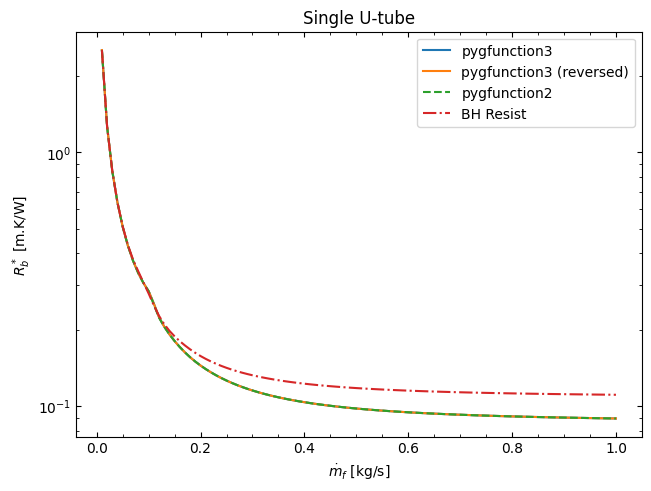

In [8]:
fig, ax = plt.subplots(constrained_layout=True)
ax = gt3.plot._format_axis(ax, [r'$\dot{m}_f$ [kg/s]', '$R_b^*$ [m.K/W]'])
ax.set_title('Single U-tube')
ax.semilogy(m_flow, R_b_eff, label='pygfunction3')
ax.semilogy(m_flow, R_b_eff_reversed, label='pygfunction3 (reversed)')
ax.semilogy(m_flow, R_b_eff_pygfunction, '--', label='pygfunction2')
ax.semilogy(m_flow, R_b_eff_bhr, '-.', label='BH Resist')
ax.legend()
plt.show()

### Double U-tube (adjacent)

In [9]:
# pygfunction v3
tic0 = perf_counter()
double_u_tube_adjacent = gt3.pipe.MultipleUTubeParallel(p_adjacent, r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)
toc0 = perf_counter()
double_u_tube_adjacent_reversed = gt3.pipe.MultipleUTubeParallel(p_adjacent[::-1], r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)
# pygfunction v2
tic1 = perf_counter()
borehole_pygfunction = gt.boreholes.Borehole(L, D, r_b, x, y)
h_fluid = np.array([
    gt.pipes.convective_heat_transfer_coefficient_circular_pipe(
        _m_flow / 2,
        r_p_in,
        fluid.viscosity(),
        fluid.density(),
        fluid.conductivity(),
        fluid.specific_heat(),
        epsilon
        )
    for _m_flow in m_flow
])
R_fluid = 1. / (h_fluid * 2. * np.pi * r_p_in)
R_pipe = gt.pipes.conduction_thermal_resistance_circular_pipe(
    r_p_in, r_p_out, k_p
)
R_fp = R_fluid + R_pipe
double_u_tube_adjacent_pygfunction = [
    gt.pipes.MultipleUTube(
        p_adjacent, r_p_in, r_p_out, borehole_pygfunction, k_s, k_b, _R_fp, 2, J=3, config="parallel"
    )
    for _R_fp in R_fp
]
toc1 = perf_counter()
# BHResist
tic2 = perf_counter()
double_u_tube_adjacent_bhr = Borehole_bhr()
double_u_tube_adjacent_bhr.init_double_u_borehole(
    borehole_diameter=2*r_b,
    pipe_outer_diameter=2*r_p_out,
    pipe_dimension_ratio=d_r,
    length=L,
    shank_space=shank,
    pipe_conductivity=k_p,
    pipe_inlet_arrangement="ADJACENT",
    grout_conductivity=k_b,
    soil_conductivity=k_s,
    fluid_type="PROPYLENEGLYCOL",
    fluid_concentration=x,
    boundary_condition="UNIFORM_BOREHOLE_WALL_TEMP",
)
toc2 = perf_counter()

In [10]:
print(f"Initialization time for pygfunction v3: {toc0 - tic0:.6f} seconds")
print(f"Initialization time for pygfunction v2: {toc1 - tic1:.6f} seconds")
print(f"Initialization time for BHResist: {toc2 - tic2:.6f} seconds")

Initialization time for pygfunction v3: 0.000138 seconds
Initialization time for pygfunction v2: 0.632580 seconds
Initialization time for BHResist: 0.000151 seconds


In [11]:
tic0 = perf_counter()
R_b_eff = np.array([double_u_tube_adjacent.effective_borehole_thermal_resistance(borehole, _m_flow) for _m_flow in m_flow])
toc0 = perf_counter()
R_b_eff_reversed = np.array([double_u_tube_adjacent_reversed.effective_borehole_thermal_resistance(borehole, -_m_flow) for _m_flow in m_flow])
toc1 = perf_counter()
R_b_eff_pygfunction = np.array([double_u_tube_adjacent_pygfunction[i].effective_borehole_thermal_resistance(_m_flow, np.array([cp_f])) for i, _m_flow in enumerate(m_flow)])
toc1 = tic2 = perf_counter()
R_b_eff_bhr = np.array([double_u_tube_adjacent_bhr.calc_bh_resist(_m_flow, T_nominal) for _m_flow in m_flow])
toc2 = perf_counter()

In [12]:
print(f"pygfunction v3 execution time: {toc0 - tic0:.6f} seconds")
print(f"pygfunction v2 execution time: {toc1 - tic1:.6f} seconds")
print(f"BHResist execution time: {toc2 - tic2:.6f} seconds")

pygfunction v3 execution time: 0.063026 seconds
pygfunction v2 execution time: 0.797855 seconds
BHResist execution time: 0.001779 seconds


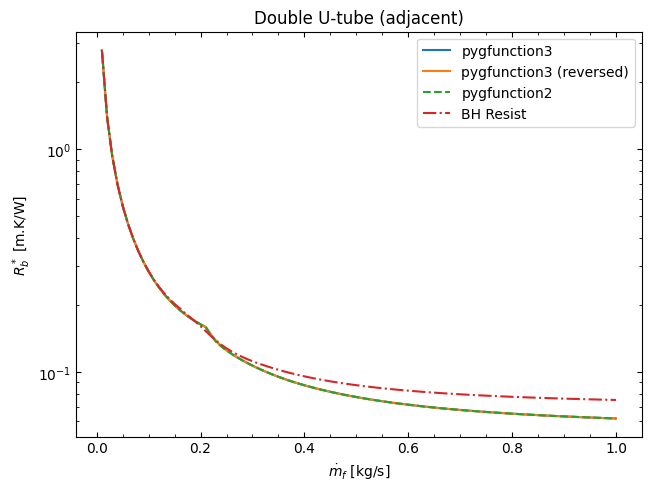

In [13]:
fig, ax = plt.subplots(constrained_layout=True)
ax = gt3.plot._format_axis(ax, [r'$\dot{m}_f$ [kg/s]', '$R_b^*$ [m.K/W]'])
ax.set_title('Double U-tube (adjacent)')
ax.semilogy(m_flow, R_b_eff, label='pygfunction3')
ax.semilogy(m_flow, R_b_eff_reversed, label='pygfunction3 (reversed)')
ax.semilogy(m_flow, R_b_eff_pygfunction, '--', label='pygfunction2')
ax.semilogy(m_flow, R_b_eff_bhr, '-.', label='BH Resist')
ax.legend()
plt.show()

### Double U-tube (diagonal)

In [14]:
# pygfunction v3
tic0 = perf_counter()
double_u_tube_diagonal = gt3.pipe.MultipleUTubeParallel(p_diagonal, r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)
toc0 = perf_counter()
double_u_tube_diagonal_reversed = gt3.pipe.MultipleUTubeParallel(p_diagonal[::-1], r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)
# pygfunction v2
tic1 = perf_counter()
borehole_pygfunction = gt.boreholes.Borehole(L, D, r_b, x, y)
h_fluid = np.array([
    gt.pipes.convective_heat_transfer_coefficient_circular_pipe(
        _m_flow / 2,
        r_p_in,
        fluid.viscosity(),
        fluid.density(),
        fluid.conductivity(),
        fluid.specific_heat(),
        epsilon
        )
    for _m_flow in m_flow
])
R_fluid = 1. / (h_fluid * 2. * np.pi * r_p_in)
R_pipe = gt.pipes.conduction_thermal_resistance_circular_pipe(
    r_p_in, r_p_out, k_p
)
R_fp = R_fluid + R_pipe
double_u_tube_diagonal_pygfunction = [
    gt.pipes.MultipleUTube(
        p_diagonal, r_p_in, r_p_out, borehole_pygfunction, k_s, k_b, _R_fp, 2, J=3, config="parallel"
    )
    for _R_fp in R_fp
]
toc1 = perf_counter()
# BHResist
tic2 = perf_counter()
double_u_tube_diagonal_bhr = Borehole_bhr()
double_u_tube_diagonal_bhr.init_double_u_borehole(
    borehole_diameter=2*r_b,
    pipe_outer_diameter=2*r_p_out,
    pipe_dimension_ratio=d_r,
    length=L,
    shank_space=shank,
    pipe_conductivity=k_p,
    pipe_inlet_arrangement="DIAGONAL",
    grout_conductivity=k_b,
    soil_conductivity=k_s,
    fluid_type="PROPYLENEGLYCOL",
    fluid_concentration=x,
    boundary_condition="UNIFORM_BOREHOLE_WALL_TEMP",
)
toc2 = perf_counter()

In [15]:
print(f"Initialization time for pygfunction v3: {toc0 - tic0:.6f} seconds")
print(f"Initialization time for pygfunction v2: {toc1 - tic1:.6f} seconds")
print(f"Initialization time for BHResist: {toc2 - tic2:.6f} seconds")

Initialization time for pygfunction v3: 0.000135 seconds
Initialization time for pygfunction v2: 0.620903 seconds
Initialization time for BHResist: 0.000161 seconds


In [16]:
tic0 = perf_counter()
R_b_eff = np.array([double_u_tube_diagonal.effective_borehole_thermal_resistance(borehole, _m_flow) for _m_flow in m_flow])
toc0 = perf_counter()
R_b_eff_reversed = np.array([double_u_tube_diagonal_reversed.effective_borehole_thermal_resistance(borehole, -_m_flow) for _m_flow in m_flow])
toc1 = perf_counter()
R_b_eff_pygfunction = np.array([double_u_tube_diagonal_pygfunction[i].effective_borehole_thermal_resistance(_m_flow, np.array([cp_f])) for i, _m_flow in enumerate(m_flow)])
toc1 = tic2 = perf_counter()
R_b_eff_bhr = np.array([double_u_tube_diagonal_bhr.calc_bh_resist(_m_flow, T_nominal) for _m_flow in m_flow])
toc2 = perf_counter()

In [17]:
print(f"pygfunction v3 execution time: {toc0 - tic0:.6f} seconds")
print(f"pygfunction v2 execution time: {toc1 - tic1:.6f} seconds")
print(f"BHResist execution time: {toc2 - tic2:.6f} seconds")

pygfunction v3 execution time: 0.061553 seconds
pygfunction v2 execution time: 0.784108 seconds
BHResist execution time: 0.001679 seconds


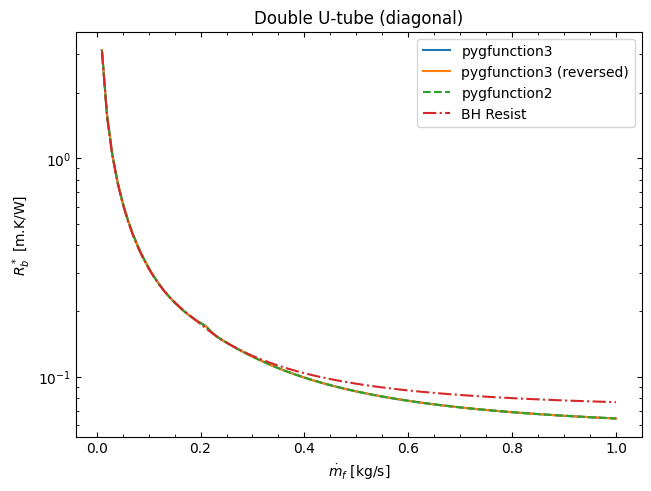

In [18]:
fig, ax = plt.subplots(constrained_layout=True)
ax = gt3.plot._format_axis(ax, [r'$\dot{m}_f$ [kg/s]', '$R_b^*$ [m.K/W]'])
ax.set_title('Double U-tube (diagonal)')
ax.semilogy(m_flow, R_b_eff, label='pygfunction3')
ax.semilogy(m_flow, R_b_eff_reversed, label='pygfunction3 (reversed)')
ax.semilogy(m_flow, R_b_eff_pygfunction, '--', label='pygfunction2')
ax.semilogy(m_flow, R_b_eff_bhr, '-.', label='BH Resist')
ax.legend()
plt.show()